# Preparation of NYC taxi data for demand forecasting

## 1. Data reading

In [1]:
# load all 2024 months of taxi rides

import polars as pl

DATA_DIR = "data"

dfs = []
for month in range(1, 13):
    df = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet")
    df = df.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    dfs.append(df)

df_2024 = pl.concat(dfs)

del dfs
df_2024 = df_2024.collect()

In [2]:
# also load taxi zone lookup data
df_taxi_zones = pl.read_csv("data/taxi_zone_lookup.csv")
df_taxi_zones

LocationID,Borough,Zone,service_zone
i64,str,str,str
1,"""EWR""","""Newark Airport""","""EWR"""
2,"""Queens""","""Jamaica Bay""","""Boro Zone"""
3,"""Bronx""","""Allerton/Pelham Gardens""","""Boro Zone"""
4,"""Manhattan""","""Alphabet City""","""Yellow Zone"""
5,"""Staten Island""","""Arden Heights""","""Boro Zone"""
…,…,…,…
261,"""Manhattan""","""World Trade Center""","""Yellow Zone"""
262,"""Manhattan""","""Yorkville East""","""Yellow Zone"""
263,"""Manhattan""","""Yorkville West""","""Yellow Zone"""


In [3]:
# include only rides starting in 2024 and ending at most at 01.01.2025

import datetime

df_2024_filtered = df.filter(
    (pl.col("tpep_pickup_datetime") >= datetime.datetime(2024, 1, 1))
    & (pl.col("tpep_dropoff_datetime") <= datetime.datetime(2025, 1, 1))
)

df_2024_filtered.describe()

statistic,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
str,f64,str,str,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3.667763e6,"""3667763""","""3667763""",3.341507e6,3.667763e6,3.341507e6,"""3341507""",3.667763e6,3.667763e6,3.667763e6,3.667763e6,3.667763e6,3.667763e6,3.667763e6,3.667763e6,3.667763e6,3.667763e6,3.341507e6,3.341507e6
"""null_count""",0.0,"""0""","""0""",326256.0,0.0,326256.0,"""326256""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,326256.0,326256.0
"""mean""",1.774706,"""2024-12-15 07:11:43.661000""","""2024-12-15 07:30:24.300000""",1.36241,5.087274,2.32853,null,164.886902,163.793562,1.133424,19.658883,1.355859,0.474636,3.459199,0.556834,0.951576,28.317542,2.221509,0.12812
"""std""",0.4227,null,null,0.823284,472.871241,10.932952,null,64.342442,69.582594,0.674558,19.815247,1.799422,0.145324,4.179993,2.247193,0.289291,24.641202,0.913618,0.475744
"""min""",1.0,"""2024-11-30 22:31:24""","""2024-11-30 22:39:27""",0.0,0.0,1.0,"""N""",1.0,1.0,0.0,-975.0,-9.25,-0.5,-80.0,-70.38,-1.0,-951.0,-2.5,-1.75
"""25%""",2.0,"""2024-12-08 00:29:22""","""2024-12-08 00:45:31""",1.0,0.97,1.0,null,132.0,113.0,1.0,9.3,0.0,0.5,0.0,0.0,1.0,15.96,2.5,0.0
"""50%""",2.0,"""2024-12-14 16:31:07""","""2024-12-14 16:52:27""",1.0,1.68,1.0,null,162.0,162.0,1.0,14.2,1.0,0.5,2.72,0.0,1.0,21.65,2.5,0.0
"""75%""",2.0,"""2024-12-21 13:12:25""","""2024-12-21 13:28:18""",1.0,3.25,1.0,null,234.0,234.0,1.0,23.9,2.5,0.5,4.48,0.0,1.0,32.1,2.5,0.0
"""max""",7.0,"""2024-12-31 23:59:21""","""2025-01-01 00:00:00""",9.0,328827.63,99.0,"""Y""",265.0,265.0,4.0,3033.1,14.25,10.5,471.0,120.15,1.0,3037.1,2.5,1.75


In [4]:
del df

In [5]:
df_2024_filtered.schema

/tmp/ipykernel_157440/688155081.py:1: PerformanceWarning: Resolving the schema of a LazyFrame is a potentially expensive operation. Use `LazyFrame.collect_schema()` to get the schema without this warning.
  df_2024_filtered.schema


Schema([('VendorID', Int32),
        ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('passenger_count', Int64),
        ('trip_distance', Float64),
        ('RatecodeID', Int64),
        ('store_and_fwd_flag', String),
        ('PULocationID', Int32),
        ('DOLocationID', Int32),
        ('payment_type', Int64),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

In [6]:
# optimize data types, particularly for integers and categorical strings
df_optimized = df_2024_filtered.with_columns(
    pl.col(
        ["VendorID", "RatecodeID", "payment_type", "PULocationID", "DOLocationID"]
    ).cast(pl.UInt16),
    pl.col("store_and_fwd_flag").cast(pl.Categorical),
)

df_optimized.schema

/tmp/ipykernel_157440/999067932.py:7: PerformanceWarning: Resolving the schema of a LazyFrame is a potentially expensive operation. Use `LazyFrame.collect_schema()` to get the schema without this warning.
  df_optimized.schema


Schema([('VendorID', UInt16),
        ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('passenger_count', Int64),
        ('trip_distance', Float64),
        ('RatecodeID', UInt16),
        ('store_and_fwd_flag', Categorical),
        ('PULocationID', UInt16),
        ('DOLocationID', UInt16),
        ('payment_type', UInt16),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

In [7]:
del df_2024_filtered

## Data cleaning and filtering

In [8]:
# fill NULL values in passengers_count with 1
# remove rides with zero passengers
# if a ride has over 6 passengers, replace the value with 6
# remove rides lasting over 2 hours
# remove rides with over 1000 dollars in any money-related column
# in all money-related columns, replace values with absolute value to fix negative amounts
# remove rows with values of RatecodeID or VendorID missing or outside those defined in the data dictionary

money_related = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

df_cleaned = df_optimized.with_columns(
    pl.col("passenger_count").fill_null(1).clip(upper_bound=6),
    pl.col(money_related).abs(),
    (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime"))
    .dt.total_minutes()
    .alias("trip_duration"),
).filter(
    (pl.col("passenger_count") > 0)
    & (pl.col("trip_duration") <= 120)
    & pl.all_horizontal(pl.col(money_related) < 1000)
    & pl.col("VendorID").is_in([1, 2, 6, 7])
    & pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99])
)

df_cleaned.describe()

statistic,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,trip_duration
str,f64,str,str,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3.30716e6,"""3307160""","""3307160""",3.30716e6,3.30716e6,3.30716e6,"""3307160""",3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6,3.30716e6
"""null_count""",0.0,"""0""","""0""",0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.779629,"""2024-12-15 06:22:01.433000""","""2024-12-15 06:39:52.372000""",1.374673,3.29757,2.306406,null,165.865408,164.765037,1.244066,20.357321,1.50809,0.492182,3.676935,0.604291,0.988616,29.563105,2.30849,0.138965,17.360354
"""std""",0.417006,null,null,0.815917,39.8604,10.836618,null,63.364035,69.342684,0.602175,18.925315,1.789648,0.062169,4.216692,2.271364,0.106089,23.566495,0.664904,0.473156,15.146369
"""min""",1.0,"""2024-11-30 22:31:24""","""2024-11-30 22:39:27""",1.0,0.0,1.0,null,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-41.0
"""25%""",2.0,"""2024-12-07 22:47:03""","""2024-12-07 23:05:40""",1.0,0.95,1.0,null,132.0,114.0,1.0,9.3,0.0,0.5,1.0,0.0,1.0,15.96,2.5,0.0,7.0
"""50%""",2.0,"""2024-12-14 15:20:29""","""2024-12-14 15:38:55""",1.0,1.63,1.0,null,162.0,162.0,1.0,14.2,1.0,0.5,2.9,0.0,1.0,21.6,2.5,0.0,13.0
"""75%""",2.0,"""2024-12-21 13:25:15""","""2024-12-21 13:40:43""",1.0,3.17,1.0,null,234.0,234.0,1.0,23.3,2.5,0.5,4.68,0.0,1.0,32.28,2.5,0.0,22.0
"""max""",7.0,"""2024-12-31 23:59:21""","""2025-01-01 00:00:00""",6.0,71761.53,99.0,null,265.0,265.0,4.0,975.0,14.25,4.0,471.0,120.15,1.0,976.0,2.5,1.75,120.0


In [9]:
del df_optimized

## Data transformation

In [10]:
# combine payment type values for "No charge", "Dispute", "Unknown" and "Voided trip" into one type, so we have only credit card, cash, or other
# replace PULocationID and DOLocationID with borough names by joining taxi zone lookup and removing unnecessary columns
# add boolean variable is_airport_ride, true if there is non-zero airport fee
# add boolean variable is_rush_hour, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays

from datetime import time


PU_zones = df_taxi_zones.select(
    pl.col("LocationID").alias("PULocationID"), pl.col("Borough").alias("PU_borough")
)
DO_zones = df_taxi_zones.select(
    pl.col("LocationID").alias("DOLocationID"), pl.col("Borough").alias("DO_borough")
)

pickup_time = pl.col("tpep_pickup_datetime").dt.time()
weekday = pl.col("tpep_pickup_datetime").dt.weekday()

df_transformed = (
    df_cleaned.collect()
    .with_columns(
        pl.when(pl.col("payment_type") == 1)
        .then(1)
        .when(pl.col("payment_type") == 2)
        .then(2)
        .otherwise(7)
        .alias("payment_type"),
        (pl.col("Airport_fee") > 0).alias("is_airport_ride"),
        (
            (weekday <= 5)
            & ((pickup_time >= time(6, 30)) & (pickup_time <= time(9, 30)))
            | ((pickup_time >= time(15, 30)) & (pickup_time <= time(20, 0)))
        ).alias("is_rush_hour"),
    )
    .join(PU_zones, on="PULocationID", how="left")
    .join(DO_zones, on="DOLocationID", how="left")
    .drop("PULocationID", "DOLocationID")
)

In [11]:
del df_cleaned

In [12]:
df_transformed.head()

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,trip_duration,is_airport_ride,is_rush_hour,PU_borough,DO_borough
u16,datetime[ms],datetime[ms],i64,f64,u16,cat,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,bool,str,str
2,2024-12-01 00:12:27,2024-12-01 00:31:12,1,9.76,1,"""N""",1,38.0,6.0,0.5,4.72,0.0,1.0,51.97,0.0,1.75,18,true,false,"""Queens""","""Brooklyn"""
2,2024-11-30 23:56:04,2024-12-01 00:28:15,1,7.62,1,"""N""",1,37.3,1.0,0.5,8.46,0.0,1.0,50.76,2.5,0.0,32,false,false,"""Manhattan""","""Manhattan"""
2,2024-12-01 00:50:35,2024-12-01 01:24:46,4,20.07,2,"""N""",2,70.0,0.0,0.5,0.0,6.94,1.0,82.69,2.5,1.75,34,true,false,"""Queens""","""Manhattan"""
2,2024-12-01 00:18:16,2024-12-01 00:33:16,3,2.34,1,"""N""",1,15.6,1.0,0.5,4.12,0.0,1.0,24.72,2.5,0.0,15,false,false,"""Manhattan""","""Manhattan"""
2,2024-12-01 00:56:13,2024-12-01 01:18:25,1,5.05,1,"""N""",1,26.8,1.0,0.5,5.0,0.0,1.0,36.8,2.5,0.0,22,false,false,"""Manhattan""","""Brooklyn"""


## Feature extraction

In [13]:
# apply dummy encoding to features:
#     payment type
#     pickup borough
#     dropoff borough
# add integer variables for counting daily events:
#     total number of rides (target variable)
#     number of airport rides
#     number of rush hour rides
# add features aggregating daily rides information:
#     average fare amount
#     median distance
#     sum of total amounts
#     total amount paid by card, cash, and other
#     total congestion surcharge
#     total number of passengers
# add time features:
#     quarter
#     month
#     day_of_month
#     day_of_week
#     is_weekend (boolean)
# add column date, indicating day with given features
# make sure to exclude other columns, unnecessary for machine learning, e.g. IDs, timestamps, unused financial information


df_extracted = (
    df_transformed.with_columns(pl.col("tpep_pickup_datetime").alias("date"))
    .group_by("date")
    .agg(
        pl.len().alias("total_no_of_rides"),
        pl.col("is_airport_ride").sum().alias("no_of_airport_rides"),
        pl.col("is_rush_hour").sum().alias("no_of_rush_hour_rides"),
        pl.col("fare_amount").mean().alias("average_fare_amount"),
        pl.col("trip_distance").median().alias("median_distance"),
        pl.col("total_amount").sum().alias("total_amounts_sum"),
        pl.col("congestion_surcharge").sum().alias("total_congestion_surcharge"),
        pl.col("passenger_count").sum().alias("total_no_of_passengers"),
        pl.when(pl.col("payment_type") == 1)
        .then(pl.col("total_amount"))
        .otherwise(0)
        .sum()
        .alias("amount_paid_by_card"),
        pl.when(pl.col("payment_type") == 2)
        .then(pl.col("total_amount"))
        .otherwise(0)
        .sum()
        .alias("amount_paid_by_cash"),
        pl.when(pl.col("payment_type") == 7)
        .then(pl.col("total_amount"))
        .otherwise(0)
        .sum()
        .alias("amount_paid_by_other"),
        pl.col("date").dt.quarter().alias("quarter"),
        pl.col("date").dt.month().alias("month"),
        pl.col("date").dt.day().alias("day_of_month"),
        pl.col("date").dt.weekday().alias("day_of_week"),
        (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
    )
    .to_dummies(columns=["payment_type", "pickup_borough", "dropoff_borough"])
)

In [14]:
del df_transformed

In [15]:
df_extracted = df_extracted.select(
    "date",
    "total_no_of_rides",
    "no_of_airport_rides",
    "no_of_rush_hour_rides",
    "average_fare_amount",
    "median_distance",
    "total_amounts_sum",
    "amount_paid_by_card",
    "amount_paid_by_cash",
    "amount_paid_by_other",
    "total_congestion_surcharge",
    "total_no_of_passengers",
    "quarter",
    "month",
    "day_of_month",
    "day_of_week",
    "is_weekend",
    pl.col("^payment_type_.*$"),
    pl.col("^PU_borough_.*$"),
    pl.col("^DO_borough_.*$"),
)

In [16]:
df_extracted.write_parquet("df_extracted.parquet")

## Data analysis

In [17]:
# print shape

df_extracted.shape

(1624353, 17)

In [18]:
# show top rows

df_extracted.head(5)

date,total_no_of_rides,no_of_airport_rides,no_of_rush_hour_rides,average_fare_amount,median_distance,total_amounts_sum,amount_paid_by_card,amount_paid_by_cash,amount_paid_by_other,total_congestion_surcharge,total_no_of_passengers,quarter,month,day_of_month,day_of_week,is_weekend
datetime[ms],u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,list[i8],list[i8],list[i8],list[i8],list[bool]
2024-12-14 08:50:44,1,0,0,9.3,1.15,15.96,15.96,0.0,0.0,2.5,4,[4],[12],[14],[6],[true]
2024-12-05 18:54:52,5,1,5,25.08,2.11,204.77,204.77,0.0,0.0,12.5,6,"[4, 4, … 4]","[12, 12, … 12]","[5, 5, … 5]","[4, 4, … 4]","[false, false, … false]"
2024-12-19 14:42:21,6,0,0,15.833333,1.005,157.13,157.13,0.0,0.0,15.0,6,"[4, 4, … 4]","[12, 12, … 12]","[19, 19, … 19]","[4, 4, … 4]","[false, false, … false]"
2024-12-23 21:52:20,1,1,0,38.7,9.33,42.95,0.0,42.95,0.0,0.0,1,[4],[12],[23],[1],[false]
2024-12-11 23:43:51,1,1,0,24.0,5.46,39.55,39.55,0.0,0.0,0.0,1,[4],[12],[11],[3],[false]


In [19]:
# describe statistics
df_extracted.describe()

statistic,date,total_no_of_rides,no_of_airport_rides,no_of_rush_hour_rides,average_fare_amount,median_distance,total_amounts_sum,amount_paid_by_card,amount_paid_by_cash,amount_paid_by_other,total_congestion_surcharge,total_no_of_passengers,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""1624353""",1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6,1.624353e6
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-12-15 20:16:53.151000""",2.035986,0.161674,0.754109,20.409049,3.150035,60.190069,50.695558,7.511202,1.983309,4.700053,2.798814,null,null,null,null,null
"""std""",null,1.217448,0.416047,1.291173,15.899412,56.431206,50.323056,46.32379,18.713056,14.810875,3.015478,2.056068,null,null,null,null,null
"""min""","""2024-11-30 22:31:24""",1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,null,null,null,null,null
"""25%""","""2024-12-08 09:31:46""",1.0,0.0,0.0,10.7,1.11,23.04,18.4,0.0,0.0,2.5,1.0,null,null,null,null,null
"""50%""","""2024-12-15 10:31:33""",2.0,0.0,0.0,15.6,1.75,44.36,36.29,0.0,0.0,5.0,2.0,null,null,null,null,null
"""75%""","""2024-12-22 16:40:10""",3.0,0.0,1.0,24.466667,3.19,82.31,70.77,8.4,0.0,5.0,4.0,null,null,null,null,null
"""max""","""2024-12-31 23:59:21""",14.0,6.0,13.0,975.0,71761.53,1927.0,712.03,1314.56,1927.0,32.5,24.0,null,null,null,null,null


In [20]:
# print schema

df_extracted.schema

Schema([('date', Datetime(time_unit='ms', time_zone=None)),
        ('total_no_of_rides', UInt32),
        ('no_of_airport_rides', UInt32),
        ('no_of_rush_hour_rides', UInt32),
        ('average_fare_amount', Float64),
        ('median_distance', Float64),
        ('total_amounts_sum', Float64),
        ('amount_paid_by_card', Float64),
        ('amount_paid_by_cash', Float64),
        ('amount_paid_by_other', Float64),
        ('total_congestion_surcharge', Float64),
        ('total_no_of_passengers', Int64),
        ('quarter', List(Int8)),
        ('month', List(Int8)),
        ('day_of_month', List(Int8)),
        ('day_of_week', List(Int8)),
        ('is_weekend', List(Boolean))])

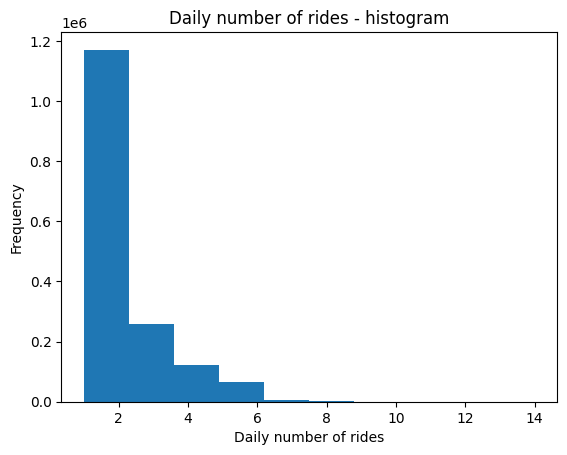

In [21]:
# plot target variable (daily number of rides):
#     histogram of values
#     line plot, date vs number of rides (remember to sort by date)

import matplotlib.pyplot as plt

df_extracted = df_extracted.select(["date", "total_no_of_rides"]).sort("date")

plt.hist(df_extracted["total_no_of_rides"])
plt.xlabel("Daily number of rides")
plt.ylabel("Frequency")
plt.title("Daily number of rides - histogram")
plt.show()

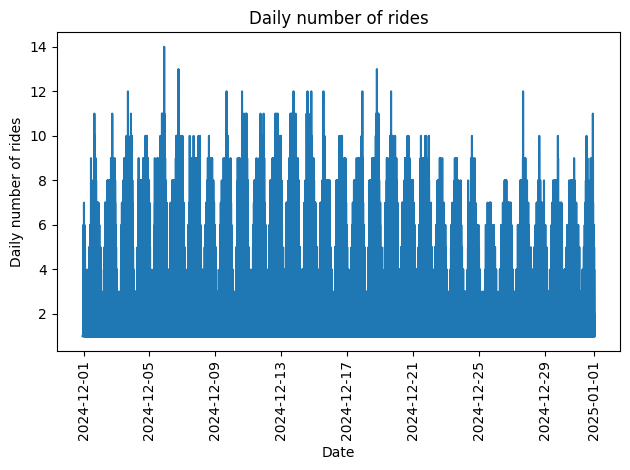

In [22]:
plt.plot(df_extracted["date"].to_list(), df_extracted["total_no_of_rides"].to_list())
plt.xlabel("Date")
plt.ylabel("Daily number of rides")
plt.title("Daily number of rides")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()